In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
from pathlib import Path
import warnings
SEED = 42
TOP_N = 5
pd.set_option('display.max_columns', 30)

In [17]:
url = 'https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/07_Visualization/Online_Retail/Online_Retail.csv'
try:
    df_raw = pd.read_csv(url, encoding='latin1')
except Exception as e:
    raise RuntimeError('No se pudo descargar el CSV. Verificá tu conexión o guardá el archivo localmente y cambiá url por su ruta.') from e
print('Dimensiones:', df_raw.shape)
print('Columnas:', df_raw.columns.tolist())
display(df_raw.head())
display(pd.DataFrame({'nulos': df_raw.isna().sum(), 'porcentaje': (100*df_raw.isna().mean()).round(2)}))
print('Duplicados exactos:', df_raw.duplicated().sum())

Dimensiones: (541909, 8)
Columnas: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


,nulos,porcentaje
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Duplicados exactos: 5268


In [21]:
url = 'https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/07_Visualization/Online_Retail/Online_Retail.csv'
try:
    df_raw = pd.read_csv(url, encoding='latin1')
except Exception as e:
    raise RuntimeError('No se pudo descargar el CSV. Verificá tu conexión o guardá el archivo localmente y cambiá url por su ruta.') from e
print('Dimensiones:', df_raw.shape)
print('Columnas:', df_raw.columns.tolist())
display(df_raw.head())
display(pd.DataFrame({'nulos': df_raw.isna().sum(), 'porcentaje': (100*df_raw.isna().mean()).round(2)}))
print('Duplicados exactos:', df_raw.duplicated().sum())

Dimensiones: (541909, 8)
Columnas: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/10 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/10 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/10 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/10 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/10 8:26,3.39,17850.0,United Kingdom


,nulos,porcentaje
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Duplicados exactos: 5268


In [23]:
df = df_raw.copy()

required = {
    'InvoiceNo', 'StockCode', 'Description',
    'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID'
}

assert required.issubset(df.columns), (
    f"Faltan columnas: {required - set(df.columns)}"
)

df['InvoiceDate'] = pd.to_datetime(
    df['InvoiceDate'].astype(str).str.strip(),
    format='%m/%d/%y %H:%M',
    errors='coerce'
)

fechas_invalidas = df['InvoiceDate'].isna().sum()
porcentaje_invalidas = df['InvoiceDate'].isna().mean() * 100

print("Fechas interpretadas:", df['InvoiceDate'].notna().sum())
print("Fechas inválidas:", fechas_invalidas)
print("Porcentaje inválido:", round(porcentaje_invalidas, 2), "%")
print("Fecha mínima:", df['InvoiceDate'].min())
print("Fecha máxima:", df['InvoiceDate'].max())

if porcentaje_invalidas > 5:
    raise ValueError("Más del 5% de fechas inválidas.")

df['InvoiceNo'] = df['InvoiceNo'].astype('string').str.strip()
df['StockCode'] = df['StockCode'].astype('string').str.strip()

for col in ['Quantity', 'UnitPrice', 'CustomerID']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

print("Filas originales:", len(df))
print("Valores faltantes:")
print(df.isna().sum())

devoluciones = (
    (df['Quantity'] <= 0) |
    (df['InvoiceNo'].str.startswith('C', na=False))
)

print("Devoluciones/cancelaciones:", devoluciones.sum())
print("Precios no positivos:", (df['UnitPrice'] <= 0).sum())
print("Clientes sin identificar:", df['CustomerID'].isna().sum())

clean = df.dropna(
    subset=[
        'InvoiceDate', 'CustomerID', 'StockCode',
        'InvoiceNo', 'Quantity', 'UnitPrice'
    ]
).copy()

clean = clean[
    (clean['Quantity'] > 0) &
    (clean['UnitPrice'] > 0) &
    (~clean['InvoiceNo'].str.startswith('C', na=False))
].copy()

clean['CustomerID'] = clean['CustomerID'].astype('int64')

clean['TotalPrice'] = (
    clean['Quantity'] * clean['UnitPrice']
)

clean = clean.sort_values(
    'InvoiceDate'
).reset_index(drop=True)

print("Filas positivas válidas:", len(clean))
print("Clientes únicos:", clean['CustomerID'].nunique())
print("Productos únicos:", clean['StockCode'].nunique())
print("Facturas únicas:", clean['InvoiceNo'].nunique())
print("Fecha inicial:", clean['InvoiceDate'].min())
print("Fecha final:", clean['InvoiceDate'].max())
print("Ventas totales:", round(clean['TotalPrice'].sum(), 2))

assert len(clean) > 0
assert clean['InvoiceDate'].notna().all()
assert (clean['Quantity'] > 0).all()
assert (clean['UnitPrice'] > 0).all()

Fechas interpretadas: 541909
Fechas inválidas: 0
Porcentaje inválido: 0.0 %
Fecha mínima: 2010-12-01 08:26:00
Fecha máxima: 2011-12-09 12:50:00
Filas originales: 541909
Valores faltantes:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Devoluciones/cancelaciones: 10624
Precios no positivos: 2517
Clientes sin identificar: 135080
Filas positivas válidas: 397884
Clientes únicos: 4338
Productos únicos: 3665
Facturas únicas: 18532
Fecha inicial: 2010-12-01 08:26:00
Fecha final: 2011-12-09 12:50:00
Ventas totales: 8911407.9


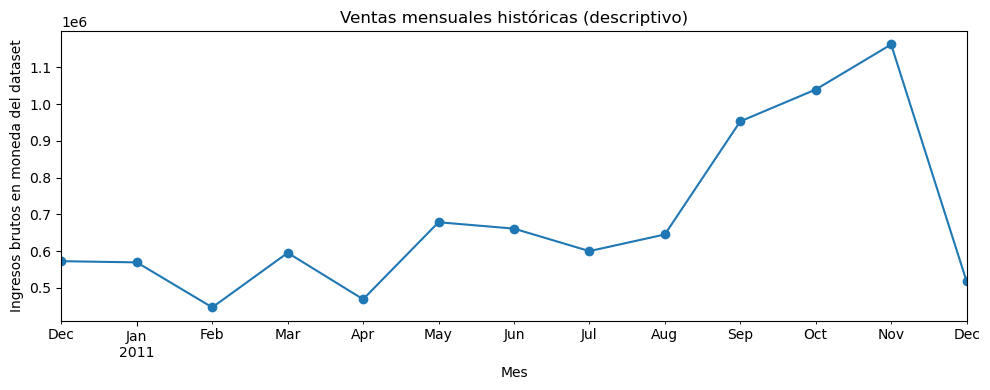

,count,mean,std,min,50%,90%,99%,max
Quantity,397884.0,12.988238,179.331775,1.000,6.00,24.00,120.00,80995.00
UnitPrice,397884.0,3.116488,22.097877,0.001,1.95,6.35,14.95,8142.75
TotalPrice,397884.0,22.397000,309.071041,0.001,11.80,35.40,202.50,168469.60


,unidades,ingresos
StockCode,,
23843,80995,168469.60
23166,77916,81416.73
84077,54415,13586.25
22197,49183,37226.43
85099B,46181,85220.78
85123A,36782,100603.50
84879,35362,56580.34
21212,33693,16394.53
23084,27202,51346.20


In [24]:
monthly = clean.set_index('InvoiceDate').resample('MS')['TotalPrice'].sum()
fig,ax=plt.subplots(figsize=(10,4)); monthly.plot(ax=ax,marker='o');ax.set(title='Ventas mensuales históricas (descriptivo)',xlabel='Mes',ylabel='Ingresos brutos en moneda del dataset');plt.tight_layout();plt.show()
display(clean[['Quantity','UnitPrice','TotalPrice']].describe(percentiles=[.5,.9,.99]).T)
display(clean.groupby('StockCode').agg(unidades=('Quantity','sum'),ingresos=('TotalPrice','sum')).sort_values('unidades',ascending=False).head(10))

In [25]:
# Dataset abarca aproximadamente un año: reservar 90 días finales para test
end = clean['InvoiceDate'].max()
test_cut = end - pd.Timedelta(days=90)
val_cut = test_cut - pd.Timedelta(days=60)
train = clean[clean.InvoiceDate < val_cut].copy()
val = clean[(clean.InvoiceDate >= val_cut)&(clean.InvoiceDate < test_cut)].copy()
test = clean[clean.InvoiceDate >= test_cut].copy()
print('Corte validación:',val_cut,'| Corte test:',test_cut)
print('Filas:',{'train':len(train),'val':len(val),'test':len(test)})
assert min(len(train),len(val),len(test))>0
assert train.InvoiceDate.max()<val.InvoiceDate.min()<=val.InvoiceDate.max()<test.InvoiceDate.min()

Corte validación: 2011-07-12 12:50:00 | Corte test: 2011-09-10 12:50:00
Filas: {'train': 181242, 'val': 55116, 'test': 161526}


In [26]:
def rfm_features(history, cutoff):
    h=history.copy()
    assert (h.InvoiceDate < cutoff).all(), 'RFM recibió compras futuras'
    g=h.groupby('CustomerID').agg(last_purchase=('InvoiceDate','max'),Frequency=('InvoiceNo','nunique'),Monetary=('TotalPrice','sum'))
    g['Recency']=(cutoff-g['last_purchase']).dt.total_seconds()/86400
    return g[['Recency','Frequency','Monetary']].copy()

def fit_segments(history, cutoff, k=4):
    r=rfm_features(history,cutoff)
    if len(r)<k: raise ValueError('Muy pocos clientes para K-Means')
    x=np.log1p(r[['Recency','Frequency','Monetary']].clip(lower=0))
    scaler=StandardScaler(); z=scaler.fit_transform(x)
    km=KMeans(n_clusters=k,random_state=SEED,n_init=10)
    r['Cluster']=km.fit_predict(z)
    summary=r.groupby('Cluster').agg(clientes=('Recency','size'),recencia_mediana=('Recency','median'),frecuencia_mediana=('Frequency','median'),gasto_mediano=('Monetary','median'))
    # Etiquetas comerciales orientativas, basadas en perfiles observados; revisar manualmente.
    score=summary['frecuencia_mediana'].rank(pct=True)+summary['gasto_mediano'].rank(pct=True)-summary['recencia_mediana'].rank(pct=True)
    ordered=score.sort_values(ascending=False).index.tolist()
    names=['VIP / alto valor','Leales / frecuentes','Nuevos / prometedores','En riesgo / inactivos']
    mapping=dict(zip(ordered,names))
    r['Segmento']=r['Cluster'].map(mapping)
    return r,summary,km,scaler
rfm_val,summary_val,km_val,scaler_val=fit_segments(train,val_cut)
display(summary_val)
print('Nota: los nombres de segmentos son hipótesis comerciales; comprobar medianas antes de reportarlos.')
# Silhouette es auxiliar: comparar 2 y 4 grupos, no usar datos de test
x=np.log1p(rfm_features(train,val_cut).clip(lower=0))
z=StandardScaler().fit_transform(x)
for k in [2,4]:
    labels=KMeans(n_clusters=k,random_state=SEED,n_init=10).fit_predict(z)
    print(f'Silhouette k={k}:',round(silhouette_score(z,labels,sample_size=min(2000,len(z)),random_state=SEED),4))

,clientes,recencia_mediana,frecuencia_mediana,gasto_mediano
Cluster,,,,
0,905,53.930556,3.0,991.380
1,381,11.961806,8.0,3104.200
2,434,12.034722,2.0,462.800
3,1304,115.850694,1.0,249.705


Nota: los nombres de segmentos son hipótesis comerciales; comprobar medianas antes de reportarlos.
Silhouette k=2: 0.4337
Silhouette k=4: 0.3597


In [27]:
class Recommenders:
    def __init__(self,history):
        self.history=history.copy()
        counts=history.groupby(['CustomerID','StockCode'])['Quantity'].sum().unstack(fill_value=0)
        self.matrix=counts
        self.users=list(counts.index);self.items=list(counts.columns)
        self.user_index={v:i for i,v in enumerate(self.users)}
        self.item_index={v:i for i,v in enumerate(self.items)}
        self.purchased={uid:set(history.loc[history.CustomerID==uid,'StockCode']) for uid in self.users}
        self.popular=history.groupby('StockCode')['Quantity'].sum().sort_values(ascending=False).index.tolist()
        # Sparse evita crear matrices gigantes de entrada; top-k se calcula bajo demanda
        self.X=csr_matrix(counts.to_numpy(dtype=np.float32))
        self.item_X=self.X.T.tocsr()
    def top_sellers(self,uid,n=5):
        seen=self.purchased.get(uid,set())
        return [p for p in self.popular if p not in seen][:n]
    def user_user(self,uid,n=5,neighbors=20):
        if uid not in self.user_index:return []
        i=self.user_index[uid]
        scores=cosine_similarity(self.X[i],self.X).ravel();scores[i]=-1
        ids=np.argsort(-scores)[:neighbors]
        seen=self.purchased[uid]
        product_scores={}
        for j in ids:
            if scores[j]<=0:continue
            row=self.X.getrow(j)
            for col,qty in zip(row.indices,row.data):
                p=self.items[col]
                if p not in seen: product_scores[p]=product_scores.get(p,0)+float(scores[j])*float(qty)
        return [p for p,_ in sorted(product_scores.items(),key=lambda x:(-x[1],str(x[0])))[:n]]
    def item_item(self,uid,n=5):
        if uid not in self.user_index:return []
        i=self.user_index[uid]; row=self.X.getrow(i)
        if row.nnz==0:return []
        # Producto-producto bajo demanda, sin construir una matriz cuadrada densa completa
        sims=cosine_similarity(self.item_X,self.item_X[row.indices])
        scores=sims @ row.data.astype(float)
        scores[row.indices]=-np.inf
        inds=np.argsort(-scores)[:n]
        return [self.items[j] for j in inds if np.isfinite(scores[j]) and scores[j]>0]

models_val=Recommenders(train)
print('Usuarios en train:',len(models_val.users),'| Productos:',len(models_val.items))
print('Ejemplo:',models_val.top_sellers(models_val.users[0],5))

Usuarios en train: 3024 | Productos: 3291
Ejemplo: ['84077', '85123A', '85099B', '21212', '22197']


In [28]:
def evaluate(models, future, segment_table=None, top_n=5):
    # Usuarios elegibles: historial previo y al menos una compra posterior
    actual=future.groupby('CustomerID')['StockCode'].agg(lambda s:set(s))
    eligible=sorted(set(models.users)&set(actual.index))
    strategies={'Top-Sellers':models.top_sellers,'Usuario-Usuario':models.user_user,'Ítem-Ítem':models.item_item}
    rows=[]; details=[]
    for name,func in strategies.items():
        all_recs=set()
        for uid in eligible:
            rec=list(dict.fromkeys(func(uid,top_n)))[:top_n]
            # Recomendaciones vacías cuentan como cero: no se eliminan clientes
            hits=len(set(rec)&actual[uid])
            all_recs.update(rec)
            rows.append({'Modelo':name,'CustomerID':uid,'Precision@5':hits/top_n,
                         'Recall@5':hits/len(actual[uid]),'HitRate@5':int(hits>0),
                         'CoberturaUsuarios':int(len(rec)>0),'CantidadRecs':len(rec)})
    detail=pd.DataFrame(rows)
    if detail.empty:raise ValueError('No hay clientes elegibles: revisar fechas o datos')
    if segment_table is not None:
        detail=detail.merge(segment_table[['Segmento']],left_on='CustomerID',right_index=True,how='left')
    summary=detail.groupby('Modelo',sort=False)[['Precision@5','Recall@5','HitRate@5','CoberturaUsuarios','CantidadRecs']].mean()
    summary['ClientesEvaluados']=len(eligible)
    return summary,detail
results_val,detail_val=evaluate(models_val,val,rfm_val)
print('VALIDACIÓN (para elegir estrategia)');display(results_val)
print('POR SEGMENTO EN VALIDACIÓN')
display(detail_val.groupby(['Segmento','Modelo'])[['Precision@5','Recall@5','HitRate@5','CoberturaUsuarios']].mean())

VALIDACIÓN (para elegir estrategia)


,Precision@5,Recall@5,HitRate@5,CoberturaUsuarios,CantidadRecs,ClientesEvaluados
Modelo,,,,,,
Top-Sellers,0.034176,0.005318,0.156931,1.0,5.0,1147
Usuario-Usuario,0.049869,0.011050,0.180471,1.0,5.0,1147
Ítem-Ítem,0.044464,0.008627,0.167393,1.0,5.0,1147


POR SEGMENTO EN VALIDACIÓN


Precision@5  Recall@5  HitRate@5  \
Segmento              Modelo                                              
En riesgo / inactivos Top-Sellers         0.044444  0.008614   0.193416   
                      Usuario-Usuario     0.052675  0.016547   0.168724   
                      Ítem-Ítem           0.042798  0.012841   0.135802   
Leales / frecuentes   Top-Sellers         0.037642  0.005520   0.176871   
                      Usuario-Usuario     0.053061  0.011614   0.195011   
                      Ítem-Ítem           0.043084  0.007927   0.176871   
Nuevos / prometedores Top-Sellers         0.024324  0.004976   0.121622   
                      Usuario-Usuario     0.044595  0.012116   0.155405   
                      Ítem-Ítem           0.048649  0.012047   0.189189   
VIP / alto valor      Top-Sellers         0.026032  0.002652   0.117460   
                      Usuario-Usuario     0.045714  0.005518   0.180952   
                      Ítem-Ítem           0.045714  0.004751   0.168254   

                                       CoberturaUsuarios  
Segmento              Modelo                              
En riesgo / inactivos Top-Sellers                    1.0  
                      Usuario-Usuario                1.0  
                      Ítem-Ítem                      1.0  
Leales / frecuentes   Top-Sellers                    1.0  
                      Usuario-Usuario                1.0  
                      Ítem-Ítem                      1.0  
Nuevos / prometedores Top-Sellers                    1.0  
                      Usuario-Usuario                1.0  
                      Ítem-Ítem                      1.0  
VIP / alto valor      Top-Sellers                    1.0  
                      Usuario-Usuario                1.0  
                      Ítem-Ítem                      1.0

In [29]:
# Criterio definido: mayor Precision@5 en validación; desempate por Recall@5
ranking=results_val.sort_values(['Precision@5','Recall@5'],ascending=False)
selected=ranking.index[0]
print('Estrategia elegida exclusivamente en validación:',selected)
# Reentrenar usando TODO el historial anterior al corte de test
history_test=clean[clean.InvoiceDate<test_cut].copy()
assert history_test.InvoiceDate.max()<test.InvoiceDate.min()
models_test=Recommenders(history_test)
rfm_test,summary_test,km_test,scaler_test=fit_segments(history_test,test_cut)
results_test,detail_test=evaluate(models_test,test,rfm_test)
print('TEST FINAL (comparación descriptiva; no cambiar la elección por estos resultados)')
display(results_test)
print('Resultado de la estrategia preseleccionada:')
display(results_test.loc[[selected]])
print('POR SEGMENTO EN TEST')
display(detail_test.groupby(['Segmento','Modelo'])[['Precision@5','Recall@5','HitRate@5','CoberturaUsuarios']].mean())

Estrategia elegida exclusivamente en validación: Usuario-Usuario
TEST FINAL (comparación descriptiva; no cambiar la elección por estos resultados)


,Precision@5,Recall@5,HitRate@5,CoberturaUsuarios,CantidadRecs,ClientesEvaluados
Modelo,,,,,,
Top-Sellers,0.037480,0.005178,0.162415,1.0,5.0,1921
Usuario-Usuario,0.051536,0.007778,0.187402,1.0,5.0,1921
Ítem-Ítem,0.043831,0.006536,0.166580,1.0,5.0,1921


Resultado de la estrategia preseleccionada:


,Precision@5,Recall@5,HitRate@5,CoberturaUsuarios,CantidadRecs,ClientesEvaluados
Modelo,,,,,,
Usuario-Usuario,0.051536,0.007778,0.187402,1.0,5.0,1921


POR SEGMENTO EN TEST


Precision@5  Recall@5  HitRate@5  \
Segmento              Modelo                                              
En riesgo / inactivos Top-Sellers         0.047655  0.009258   0.206379   
                      Usuario-Usuario     0.058912  0.011505   0.204503   
                      Ítem-Ítem           0.043902  0.010275   0.170732   
Leales / frecuentes   Top-Sellers         0.033232  0.003977   0.144817   
                      Usuario-Usuario     0.054268  0.006629   0.205793   
                      Ítem-Ítem           0.043598  0.005511   0.169207   
Nuevos / prometedores Top-Sellers         0.031359  0.003801   0.128920   
                      Usuario-Usuario     0.048084  0.010400   0.170732   
                      Ítem-Ítem           0.034146  0.005210   0.125436   
VIP / alto valor      Top-Sellers         0.035506  0.002948   0.157303   
                      Usuario-Usuario     0.040899  0.003318   0.150562   
                      Ítem-Ítem           0.050337  0.004424   0.184270   

                                       CoberturaUsuarios  
Segmento              Modelo                              
En riesgo / inactivos Top-Sellers                    1.0  
                      Usuario-Usuario                1.0  
                      Ítem-Ítem                      1.0  
Leales / frecuentes   Top-Sellers                    1.0  
                      Usuario-Usuario                1.0  
                      Ítem-Ítem                      1.0  
Nuevos / prometedores Top-Sellers                    1.0  
                      Usuario-Usuario                1.0  
                      Ítem-Ítem                      1.0  
VIP / alto valor      Top-Sellers                    1.0  
                      Usuario-Usuario                1.0  
                      Ítem-Ítem                      1.0

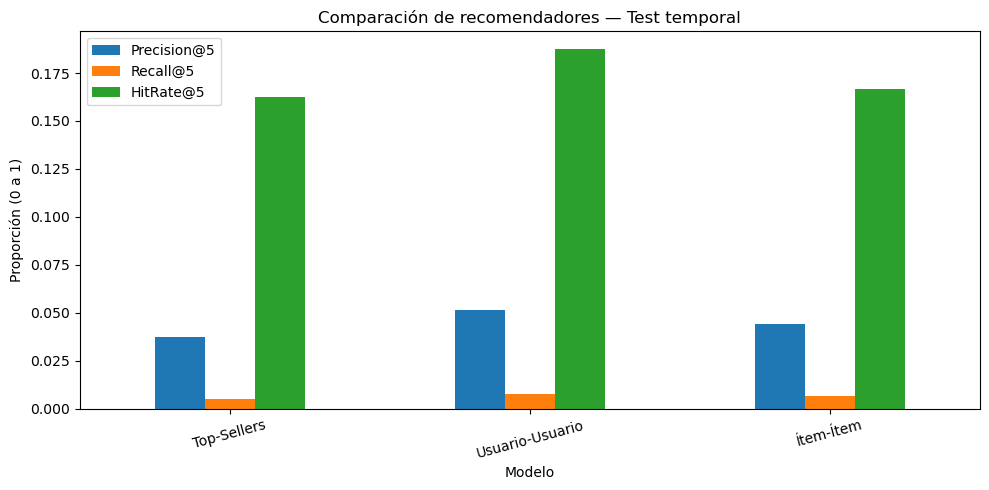

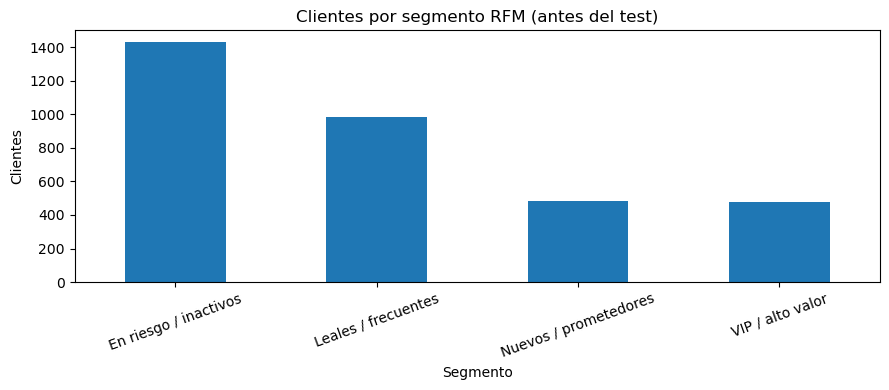

Perfiles de los 4 clústeres (test):


,clientes,recencia_mediana,frecuencia_mediana,gasto_mediano
Cluster,,,,
0,982,68.032639,3.0,1070.120
1,1429,155.217361,1.0,251.020
2,481,15.121528,2.0,541.510
3,478,10.855903,9.0,3234.405


Gasto mediano por segmento (historia anterior al test):


,clientes,gasto_mediano,frecuencia_mediana,recencia_mediana
Segmento,,,,
En riesgo / inactivos,1429,251.020,1.0,155.217361
Leales / frecuentes,982,1070.120,3.0,68.032639
Nuevos / prometedores,481,541.510,2.0,15.121528
VIP / alto valor,478,3234.405,9.0,10.855903


CSV exportados en el directorio de trabajo.


In [30]:
ax=results_test[['Precision@5','Recall@5','HitRate@5']].plot(kind='bar',figsize=(10,5),rot=15)
ax.set(title='Comparación de recomendadores — Test temporal',ylabel='Proporción (0 a 1)');plt.tight_layout();plt.show()
ax=rfm_test['Segmento'].value_counts().plot(kind='bar',figsize=(9,4),rot=20)
ax.set(title='Clientes por segmento RFM (antes del test)',ylabel='Clientes');plt.tight_layout();plt.show()
print('Perfiles de los 4 clústeres (test):');display(summary_test)
print('Gasto mediano por segmento (historia anterior al test):')
display(rfm_test.groupby('Segmento').agg(clientes=('Monetary','size'),gasto_mediano=('Monetary','median'),frecuencia_mediana=('Frequency','median'),recencia_mediana=('Recency','median')))
results_val.to_csv('metricas_validacion.csv',encoding='utf-8-sig')
results_test.to_csv('metricas_test.csv',encoding='utf-8-sig')
detail_test.groupby(['Segmento','Modelo'])[['Precision@5','Recall@5','HitRate@5','CoberturaUsuarios']].mean().to_csv('metricas_por_segmento.csv',encoding='utf-8-sig')
print('CSV exportados en el directorio de trabajo.')